# EDA: 2008 Global Financial Crisis

**Owner:** Rishi · **Week 1** · Market Stress Early-Warning System

**Goal:** understand what U.S. equity market stress looked like in 2007 to 2009 at the stock level, check the quality of our price data for this period (especially survivorship bias), and get a first look at whether connectedness rose *before* the worst of the stress or only during it.

**Before running:** run `python scripts/download_sp500_prices.py` from the repo root. This notebook reads `data/processed/`. If `data/processed/daily_panel.parquet` from `01_data_collection.ipynb` exists, the FRED stress index is added to the plots.

**Window:** 2007-01-01 to 2009-12-31, with 2006 loaded as warm-up for rolling windows.

Reference dates used for chart markers (verify against a primary source before citing them in the report):

| Date | Event |
|---|---|
| 2007-08-09 | BNP Paribas freezes withdrawals from funds exposed to U.S. subprime mortgages |
| 2007-10-09 | S&P 500 closing high before the crisis |
| 2008-03-16 | JPMorgan agrees to acquire Bear Stearns with Federal Reserve support |
| 2008-09-15 | Lehman Brothers files for bankruptcy |
| 2009-03-09 | S&P 500 closing low |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prices as px

PROC = ROOT / "data" / "processed"
WARMUP, START, END = "2006-01-01", "2007-01-01", "2009-12-31"

EVENTS = {
    "2007-08-09": "BNP Paribas",
    "2007-10-09": "S&P peak",
    "2008-03-16": "Bear Stearns",
    "2008-09-15": "Lehman",
    "2009-03-09": "S&P low",
}

def mark_events(ax, labels=True):
    for d, lab in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
        if labels:
            ax.text(pd.Timestamp(d), 1.0, f" {lab}", transform=ax.get_xaxis_transform(),
                    rotation=90, va="top", ha="left", fontsize=8, color="grey")

pd.set_option("display.width", 140)

## 1. Load data

In [2]:
close = pd.read_parquet(PROC / "sp500_close.parquet").loc[WARMUP:END]
membership = pd.read_parquet(PROC / "sp500_membership.parquet").loc[WARMUP:END]
report = pd.read_csv(PROC / "sp500_coverage_report.csv", index_col="ticker",
                     parse_dates=["first_price", "last_price", "first_member_day"])

# Daily simple returns from unmasked prices, then keep member days only,
# so a stock's first day back in the index still has a valid return.
stock_cols = membership.columns
rets_all = close.reindex(columns=stock_cols).pct_change(fill_method=None)
rets = rets_all.where(membership)

gspc = close["^GSPC"]
print(f"{close.index.min().date()} to {close.index.max().date()}: {len(close)} trading days")
print(f"{len(stock_cols)} tickers were members at some point in the full download period")

2006-01-03 to 2009-12-31: 1007 trading days
977 tickers were members at some point in the full download period


## 2. Data quality: how much of the index do we actually see?

This is the survivorship check. On each day, what share of the stocks that were *in the index that day* have a Yahoo price?

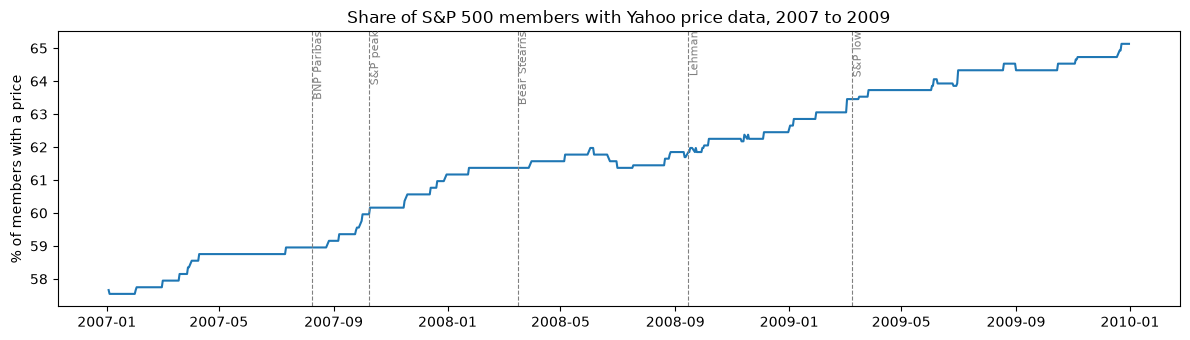

Average share priced, full window:      61.6%
Average share priced, Sep 2008-Mar 2009: 62.6%
Lowest daily share: 57.5% on 2007-01-04


In [3]:
cov = px.coverage_by_day(close, membership).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["share_priced"] * 100)
ax.set_ylabel("% of members with a price")
ax.set_title("Share of S&P 500 members with Yahoo price data, 2007 to 2009")
mark_events(ax)
plt.tight_layout(); plt.show()

crisis = cov.loc["2008-09-01":"2009-03-31"]
print(f"Average share priced, full window:      {cov['share_priced'].mean():.1%}")
print(f"Average share priced, Sep 2008-Mar 2009: {crisis['share_priced'].mean():.1%}")
print(f"Lowest daily share: {cov['share_priced'].min():.1%} on {cov['share_priced'].idxmin().date()}")

In [4]:
# Members during the window with no or partial price data, ranked by days in the index during the window
win_mem = membership.loc[START:END]
win_has = close.reindex(columns=stock_cols).loc[START:END].notna() & win_mem
gap = pd.DataFrame({
    "member_days_in_window": win_mem.sum(),
    "priced_days_in_window": win_has.sum(),
})
gap = gap[gap["member_days_in_window"] > 0]
gap["coverage_in_window"] = (gap["priced_days_in_window"] / gap["member_days_in_window"]).round(3)
missing = gap[gap["coverage_in_window"] < 1].sort_values("member_days_in_window", ascending=False)
print(f"{len(missing)} of {len(gap)} window members have incomplete prices; "
      f"{int((gap['priced_days_in_window'] == 0).sum())} have none")
missing.head(30)

255 of 597 window members have incomplete prices; 253 have none


,member_days_in_window,priced_days_in_window,coverage_in_window
AABA,756,0,0.000
LEG,756,0,0.000
LLTC,756,0,0.000
LM,756,0,0.000
LSI,756,0,0.000
LXK,756,0,0.000
MDP,756,0,0.000
MHS,756,0,0.000
MI,756,0,0.000
MIL,756,0,0.000


*Note for the write-up:* look at the tickers above. If the missing names are concentrated among failed or acquired financial firms, record that in `docs/survivorship_bias.md`: our 2008 stress measures likely **understate** the true stress.

## 3. Market overview: level, drawdown and volatility

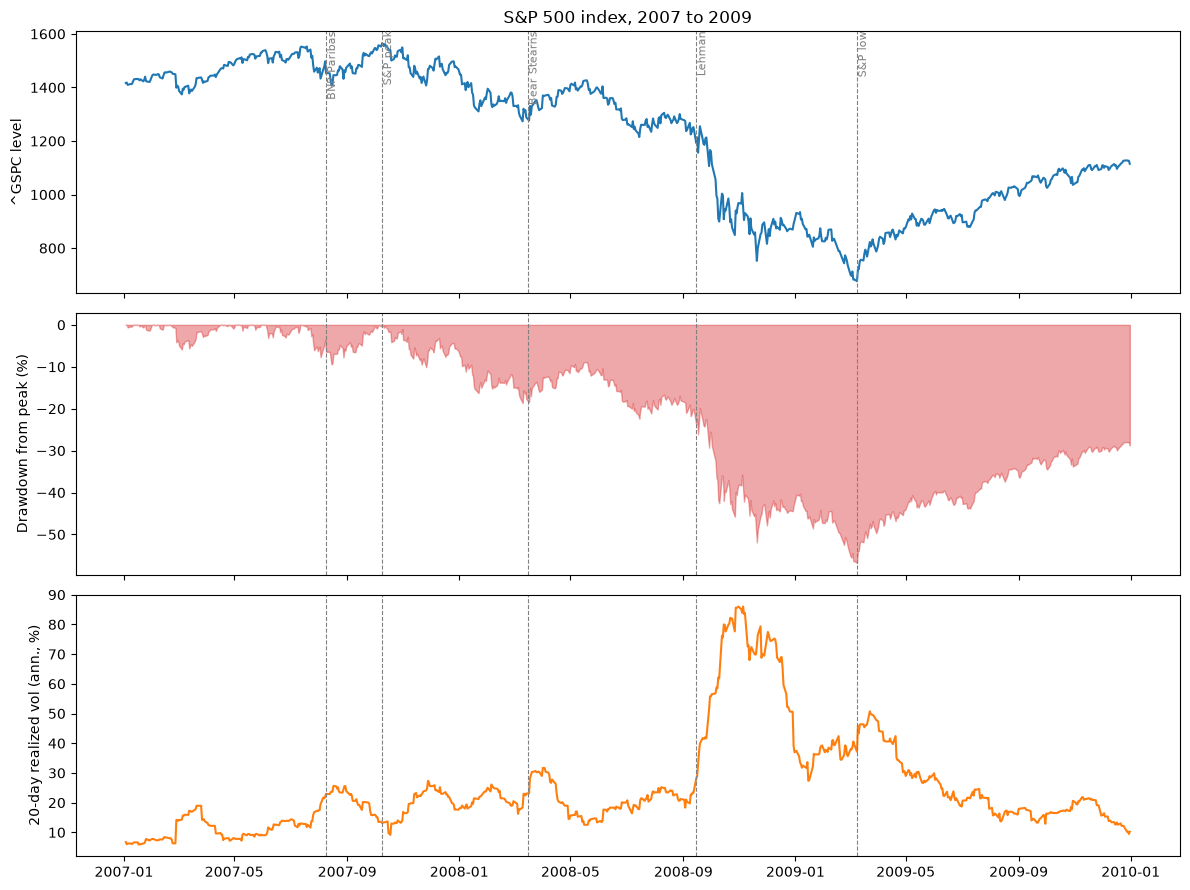

Peak close in window: 1,565.15 on 2007-10-09
Trough close in window: 676.53 on 2009-03-09
Maximum drawdown: -56.8%
Highest 20-day realized vol: 86.0% on 2008-11-05


In [5]:
g = gspc.loc[START:END]
drawdown = g / g.cummax() - 1
vol20 = gspc.pct_change(fill_method=None).rolling(20).std().loc[START:END] * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g); axes[0].set_ylabel("^GSPC level")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
axes[1].set_ylabel("Drawdown from peak (%)")
axes[2].plot(vol20.index, vol20 * 100, color="tab:orange"); axes[2].set_ylabel("20-day realized vol (ann., %)")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("S&P 500 index, 2007 to 2009")
plt.tight_layout(); plt.show()

print(f"Peak close in window: {g.max():,.2f} on {g.idxmax().date()}")
print(f"Trough close in window: {g.min():,.2f} on {g.idxmin().date()}")
print(f"Maximum drawdown: {drawdown.min():.1%}")
print(f"Highest 20-day realized vol: {vol20.max():.1%} on {vol20.idxmax().date()}")

## 4. Sanity check: equal-weighted member portfolio vs the index

The official index is cap-weighted, so the two lines should move together but not match. A large, persistent gap would point to a data problem. Because the stocks we are missing are mostly ones that failed, the equal-weighted line is expected to look somewhat *better* than reality.

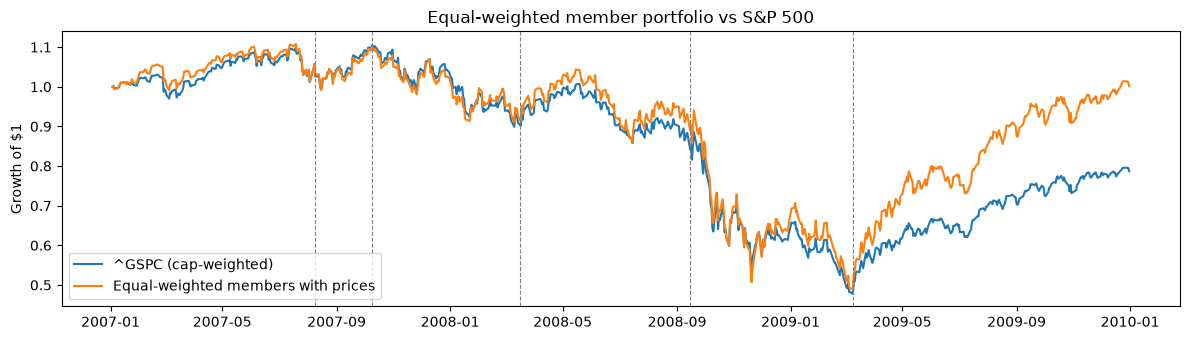

Correlation of daily returns (EW vs ^GSPC): 0.986


In [6]:
ew = rets.loc[START:END].mean(axis=1, skipna=True)
ew_level = (1 + ew.fillna(0)).cumprod()
ix_level = g / g.iloc[0]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(ix_level.index, ix_level, label="^GSPC (cap-weighted)")
ax.plot(ew_level.index, ew_level, label="Equal-weighted members with prices")
ax.set_ylabel("Growth of $1"); ax.legend(); mark_events(ax, labels=False)
ax.set_title("Equal-weighted member portfolio vs S&P 500")
plt.tight_layout(); plt.show()

daily_corr = ew.corr(gspc.pct_change(fill_method=None).loc[START:END])
print(f"Correlation of daily returns (EW vs ^GSPC): {daily_corr:.3f}")

## 5. Cross-section: dispersion and breadth

* **Dispersion:** standard deviation of returns across stocks each day. High dispersion means stocks are moving very differently.
* **Breadth:** share of members trading above their own 50-day moving average.

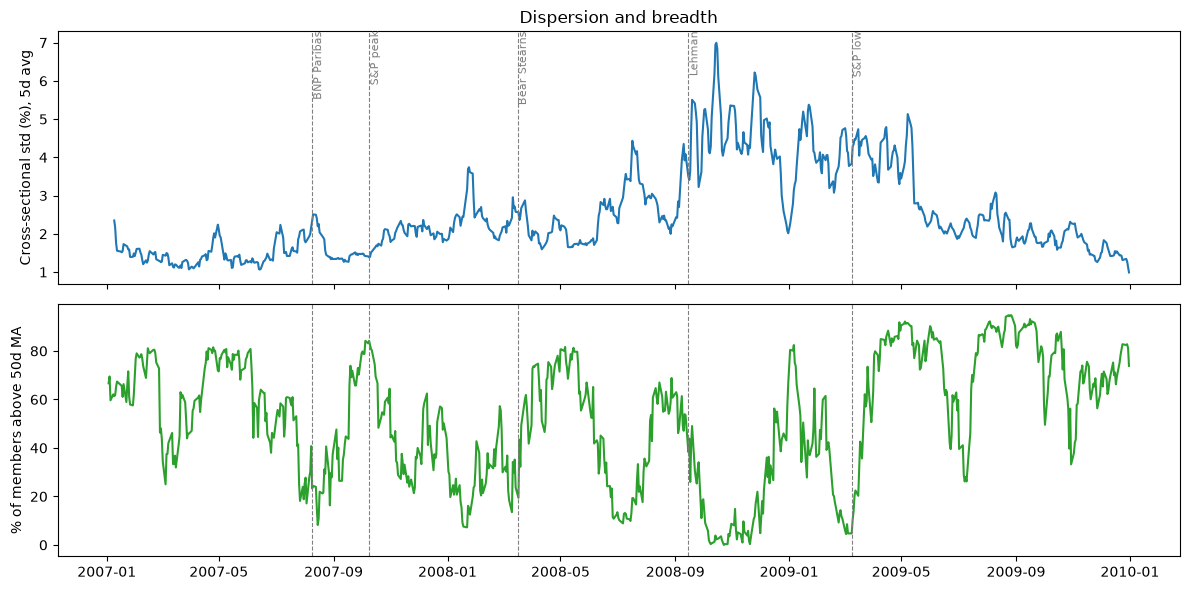

In [7]:
dispersion = rets.loc[START:END].std(axis=1, skipna=True)
ma50 = close.reindex(columns=stock_cols).rolling(50, min_periods=50).mean()
above = (close.reindex(columns=stock_cols) > ma50).where(membership & ma50.notna())
breadth = above.mean(axis=1, skipna=True).loc[START:END]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(dispersion.index, dispersion.rolling(5).mean() * 100)
axes[0].set_ylabel("Cross-sectional std (%), 5d avg")
axes[1].plot(breadth.index, breadth * 100, color="tab:green")
axes[1].set_ylabel("% of members above 50d MA")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Dispersion and breadth")
plt.tight_layout(); plt.show()

## 6. Connectedness: did stocks start moving together before the worst of the stress?

For every 5th trading day, take the previous 60 trading days of returns for stocks that were members with complete data over that window, and compute:

* **Average pairwise correlation** (the mean of the off-diagonal entries of the correlation matrix)
* **First principal component variance share**: the largest eigenvalue of the correlation matrix divided by the number of stocks. This is a one-component version of the absorption ratio idea in Kritzman et al. (2011); Fatima adds the full absorption ratio in Week 4.

This is a first look, not a forecast test.

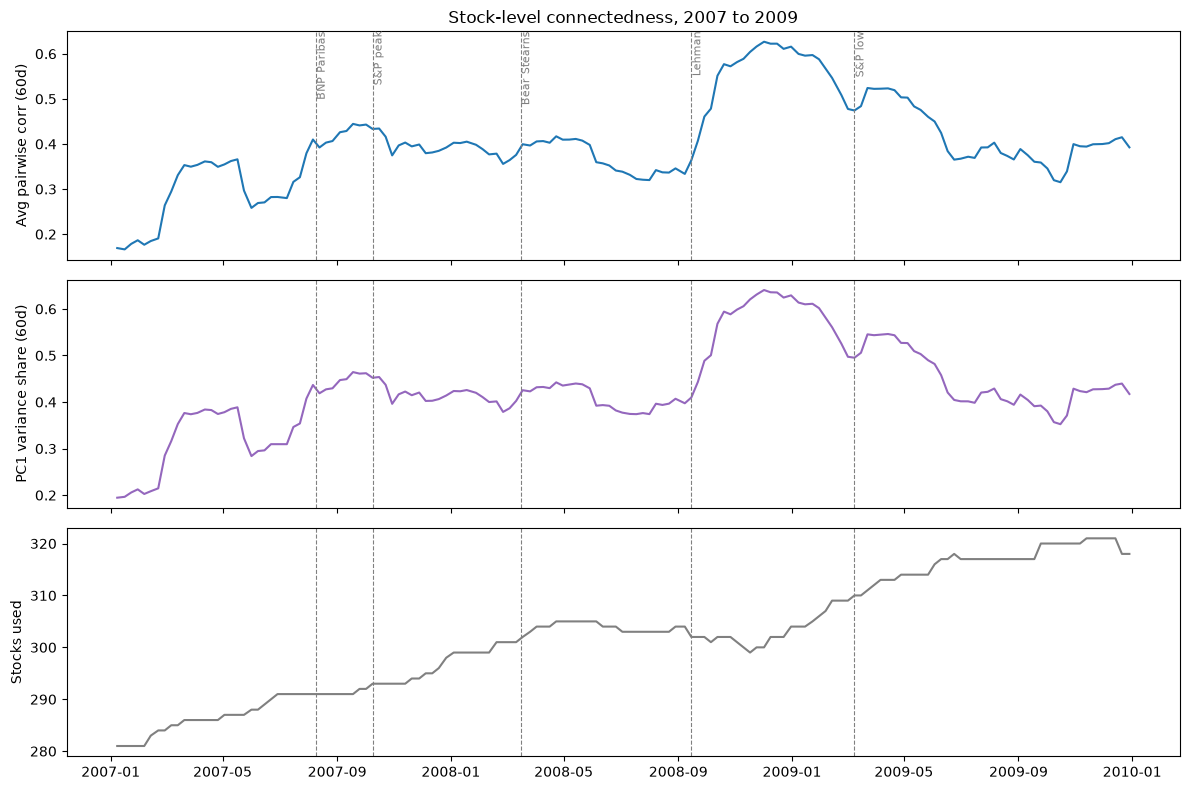

In [8]:
def connectedness(returns: pd.DataFrame, window: int = 60, step: int = 5, min_stocks: int = 100) -> pd.DataFrame:
    rows = {}
    idx = returns.index
    for end in range(window, len(idx) + 1, step):
        block = returns.iloc[end - window:end]
        block = block.loc[:, block.notna().all()]          # complete data over the window only
        block = block.loc[:, block.std() > 0]
        n = block.shape[1]
        if n < min_stocks:
            continue
        c = np.corrcoef(block.values, rowvar=False)
        avg = (c.sum() - n) / (n * (n - 1))
        top = np.linalg.eigvalsh(c)[-1] / n
        rows[idx[end - 1]] = {"avg_corr": avg, "pc1_share": top, "n_stocks": n}
    return pd.DataFrame(rows).T

conn = connectedness(rets.loc[WARMUP:END]).loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(conn.index, conn["avg_corr"]); axes[0].set_ylabel("Avg pairwise corr (60d)")
axes[1].plot(conn.index, conn["pc1_share"], color="tab:purple"); axes[1].set_ylabel("PC1 variance share (60d)")
axes[2].plot(conn.index, conn["n_stocks"], color="grey"); axes[2].set_ylabel("Stocks used")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Stock-level connectedness, 2007 to 2009")
plt.tight_layout(); plt.show()

### Optional: compare with the St. Louis Fed Financial Stress Index

Runs only if `daily_panel.parquet` from `01_data_collection.ipynb` exists. The index is weekly; this notebook forward-fills it onto trading days by observation date, which is fine for EDA but **not** for modeling (release lag, see the note in `01_data_collection.ipynb`).

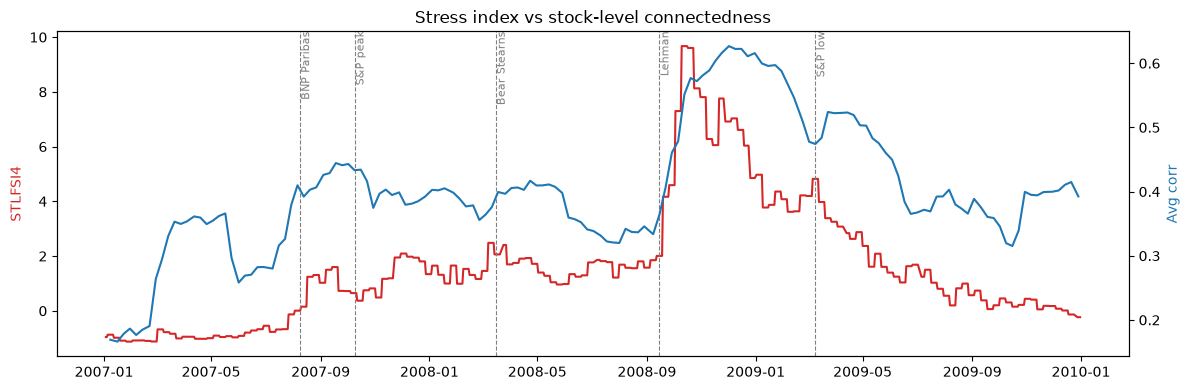

In [9]:
panel_path = PROC / "daily_panel.parquet"
stl = None
if panel_path.exists():
    panel = pd.read_parquet(panel_path)
    if "STLFSI4" in panel:
        stl = panel["STLFSI4"].ffill().reindex(close.index, method="ffill").loc[START:END]

if stl is None:
    print("daily_panel.parquet (with STLFSI4) not found; run 01_data_collection.ipynb to add this comparison.")
else:
    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(stl.index, stl, color="tab:red", label="STLFSI4"); ax1.set_ylabel("STLFSI4", color="tab:red")
    ax2 = ax1.twinx()
    ax2.plot(conn.index, conn["avg_corr"], color="tab:blue", label="Avg pairwise corr"); ax2.set_ylabel("Avg corr", color="tab:blue")
    mark_events(ax1)
    ax1.set_title("Stress index vs stock-level connectedness")
    plt.tight_layout(); plt.show()

## 7. Timing table: when did each measure first get unusual?

For each measure, the first date in the window when it exceeded its 2006 (pre-crisis) mean by 2 standard deviations, plus the date of its peak. This is a rough way to compare timing, not a formal lead-time test (that comes in Week 6 with labeled stress periods). The 2-standard-deviation rule is an arbitrary EDA choice.

In [10]:
pre = slice("2006-01-01", "2006-12-31")
conn_full = connectedness(rets.loc[WARMUP:END])
vol20_full = gspc.pct_change(fill_method=None).rolling(20).std() * np.sqrt(252)
disp_full = rets.std(axis=1, skipna=True).rolling(5).mean()

measures = {
    "20d realized vol": vol20_full,
    "dispersion (5d avg)": disp_full,
    "avg pairwise corr": conn_full["avg_corr"],
    "PC1 variance share": conn_full["pc1_share"],
}
if stl is not None:
    measures["STLFSI4"] = panel["STLFSI4"].ffill().reindex(close.index, method="ffill")

rows = {}
for name, s in measures.items():
    s = s.astype(float)
    base = s.loc[pre]
    thr = base.mean() + 2 * base.std()
    w = s.loc[START:END]
    hit = w[w > thr]
    rows[name] = {
        "2006 mean": round(base.mean(), 4),
        "threshold (mean + 2 sd)": round(thr, 4),
        "first date above threshold": hit.index[0].date() if len(hit) else None,
        "peak date": w.idxmax().date(),
    }
timing = pd.DataFrame(rows).T
timing

,2006 mean,threshold (mean + 2 sd),first date above threshold,peak date
20d realized vol,0.0978,0.1535,2007-03-06,2008-11-05
dispersion (5d avg),0.0154,0.0252,2007-01-04,2008-10-15
avg pairwise corr,0.2352,0.3713,2007-07-30,2008-12-02
PC1 variance share,0.266,0.3952,2007-07-30,2008-12-02
STLFSI4,-0.9329,-0.7233,2007-03-02,2008-10-10


## 8. Robustness: does a fixed, survivor-style panel change the connectedness picture?

Section 6 uses a rolling universe: whichever stocks were members with data in each 60-day window. Here we recompute it using only stocks that were members **and** had a price on **every** trading day from 2007 to 2009. That fixed panel is what a survivorship-biased dataset would give us. If the two lines differ a lot, our network results are sensitive to how we handle index changes and missing firms.

Fixed panel: 269 stocks present and priced on all 756 trading days


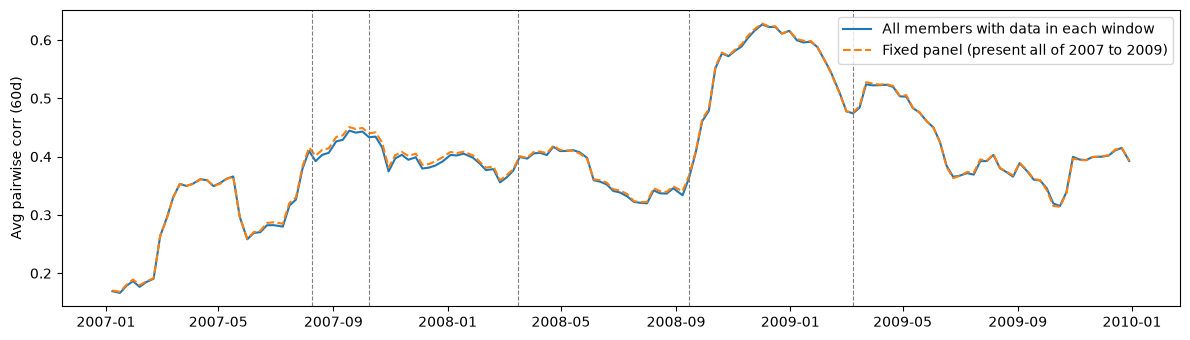

Max absolute difference in avg corr: 0.0092


/var/folders/x3/1yphdl8177j5_g_gybtgsl8r0000gn/T/ipykernel_2308/3118775355.py:12: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = conn[["avg_corr"]].join(conn_full_cov[["avg_corr"]], rsuffix="_full_cov").dropna()


In [11]:
n_days = len(win_mem)
fixed = gap.index[(gap["member_days_in_window"] == n_days) & (gap["priced_days_in_window"] == n_days)]
print(f"Fixed panel: {len(fixed)} stocks present and priced on all {n_days} trading days")
conn_full_cov = connectedness(rets.loc[WARMUP:END, fixed]).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(conn.index, conn["avg_corr"], label="All members with data in each window")
ax.plot(conn_full_cov.index, conn_full_cov["avg_corr"], label="Fixed panel (present all of 2007 to 2009)", ls="--")
ax.set_ylabel("Avg pairwise corr (60d)"); ax.legend(); mark_events(ax, labels=False)
plt.tight_layout(); plt.show()

both = conn[["avg_corr"]].join(conn_full_cov[["avg_corr"]], rsuffix="_full_cov").dropna()
print(f"Max absolute difference in avg corr: {(both['avg_corr'] - both['avg_corr_full_cov']).abs().max():.4f}")

## 9. Observations

Every point comes from this notebook's outputs. Section numbers refer to this notebook.

1. **Data coverage:** Yahoo has prices for only about 61% of S&P 500 members from 2007 to 2009 (61.8% from September 2008 to March 2009, Section 2). Most missing firms were acquired or failed, and some are renamed tickers (now partly fixed in `src/universe.py`, see `docs/survivorship_bias.md`). Stress measures for 2008 likely understate true stress.
2. **Timing of stress:** Realized volatility first exceeded its 2006 baseline threshold on 2007-03-06 and peaked on 2008-11-05 (Section 7).
3. **Connectedness:** Average pairwise correlation rose from about 0.17 to about 0.40 during 2007, first crossing the threshold on 2007-07-30, before the BNP Paribas freeze (Sections 6 and 7). However, it dipped in summer 2008 and spiked only after Lehman, peaking on 2008-12-02. Connectedness signaled a change in regime early but did not give advance warning of the acute phase.
4. **Cross-section (read from the Section 5 chart, so values are approximate):** Dispersion stayed near 1 to 2% through 2007, rose in steps through 2008 (brief spikes to about 3.7% in early 2008 and about 4.4% in July 2008), jumped above 5% at Lehman and peaked near 7% in October to November 2008. It stayed around 4 to 5% until the March 2009 low, then fell back to about 2%. Breadth fell to roughly 10% of members above their 50-day average at the BNP Paribas freeze, hit lows near 7 to 10% in early and mid 2008, fell to almost 0% in October to November 2008 and to about 5% at the March 2009 low, then recovered to about 90% by May 2009. Dispersion's first threshold crossing (2007-01-04, Section 7) likely reflects the threshold choice rather than a real signal.
5. **Robustness:** Results were nearly identical between the rolling universe and a fixed 265-stock panel (maximum difference in average correlation 0.0094, Section 8).
6. **Implications for the model:** Connectedness may be more useful as a slow-moving regime indicator than as a short-horizon alarm. The Week 6 lead-time tests should check both short and long horizons.


In [12]:
out = PROC / "eda_2008"
out.mkdir(parents=True, exist_ok=True)
conn.to_csv(out / "connectedness_60d.csv")
cov.to_csv(out / "coverage_by_day.csv")
missing.to_csv(out / "members_missing_prices.csv")
timing.to_csv(out / "timing_table.csv")
print("Saved to", out.relative_to(ROOT))

Saved to data/processed/eda_2008
